<a href="https://colab.research.google.com/github/victorNascimentoAguiar/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/Atividade%202/atividade_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear múltipla: preço de casas na Califórnia

Nesta atividade eu parto do notebook 2.6 (salários) e levo a mesma ideia para um problema mais realista: em vez de uma única variável de entrada, agora são **8**, e o objetivo é prever o preço mediano das casas de um quarteirão da Califórnia.

O que muda em relação ao 2.6 é pouca coisa no código, só que o modelo vira `nn.Linear(8, 1)` (8 pesos + 1 bias) e a divisão dos dados passa a ter também um conjunto de **teste**, que só vou usar no final. O resto do pipeline é o que já conhecemos: padronizar, treinar com `nn.MSELoss` + `optim.SGD`, olhar as curvas de treino e validação.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

O dataset vem direto do scikit-learn (é só baixar, sem login). Cada linha é um **quarteirão** (block group) do censo de 1990 da Califórnia, e o alvo é o valor mediano das casas ali.

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # y em centenas de milhares de dólares

print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### O que cada variável significa

| Variável | Significado |
|---|---|
| `MedInc` | renda mediana das famílias do quarteirão (em dezenas de milhares de dólares) |
| `HouseAge` | idade mediana das casas (em anos) |
| `AveRooms` | média de cômodos por domicílio |
| `AveBedrms` | média de quartos de dormir por domicílio |
| `Population` | número de moradores do quarteirão |
| `AveOccup` | média de moradores por domicílio |
| `Latitude` | latitude do quarteirão (quanto maior, mais ao norte) |
| `Longitude` | longitude do quarteirão (quanto mais negativa, mais a oeste, perto do litoral) |

E o alvo, `MedHouseVal`, é o **valor mediano das casas**, em unidades de 100 mil dólares. Ou seja, um `y = 2.5` quer dizer 250 mil dólares. Mais pra frente vou converter o erro para dólares de verdade.

In [3]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


In [4]:
y.describe()

,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


Dois detalhes que chamam atenção aí em cima. Primeiro, as escalas são bem diferentes: `Population` vai até as dezenas de milhares, enquanto `MedInc` fica entre 0 e 15. Isso já é um bom motivo para padronizar. Segundo, tem alguns valores esquisitos, como `AveRooms` e `AveOccup` com máximos muito acima do 75% (dá para ver pelo `describe()`), provavelmente quarteirões com pouquíssimas casas ou com hotéis/alojamentos. E o preço tem um teto em 5.0 (500 mil dólares): casas mais caras que isso foram todas registradas como 5.0, o que vai atrapalhar um pouco o modelo.

### Gráficos de dispersão contra o preço

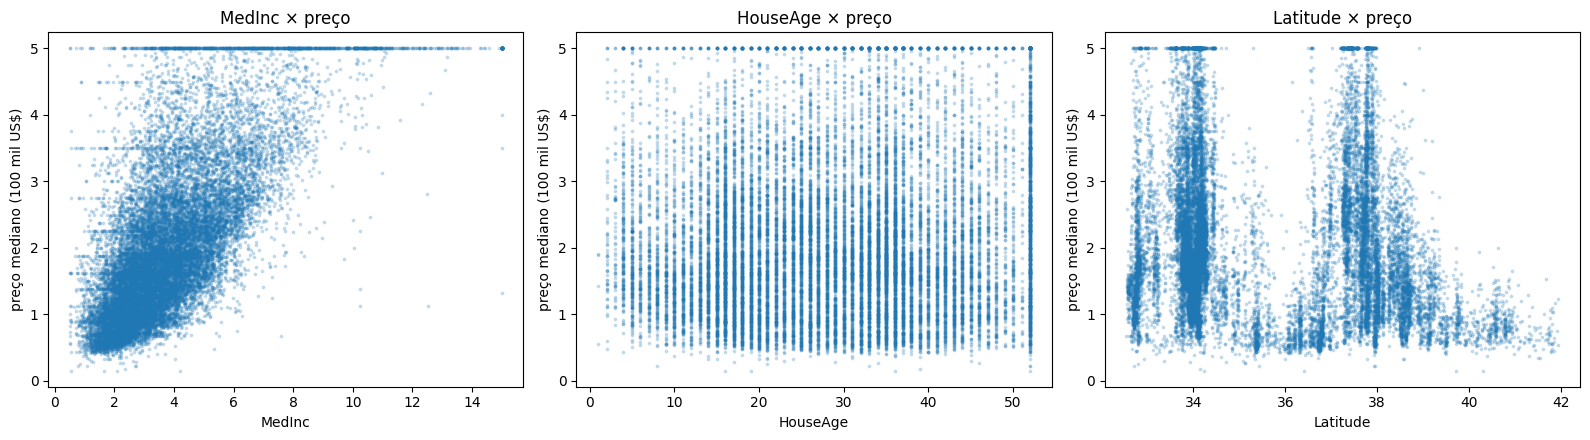

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axs, ['MedInc', 'HouseAge', 'Latitude']):
    ax.scatter(X[col], y, s=3, alpha=0.2)
    ax.set_xlabel(col)
    ax.set_ylabel('preço mediano (100 mil US$)')
    ax.set_title(f'{col} × preço')
plt.tight_layout()
plt.show()

A renda mediana é a que mais salta aos olhos: quanto mais rico o quarteirão, mais caras as casas, com uma tendência quase linear (e aquela faixa horizontal em 5.0 é o teto que comentei). `HouseAge` mal mostra relação com o preço. Já a latitude forma "ilhas" de preço, o que faz sentido porque ela está ligada a *onde* na Califórnia o quarteirão fica (Bay Area e Los Angeles são caras). Pra enxergar isso melhor, dá para plotar o mapa:

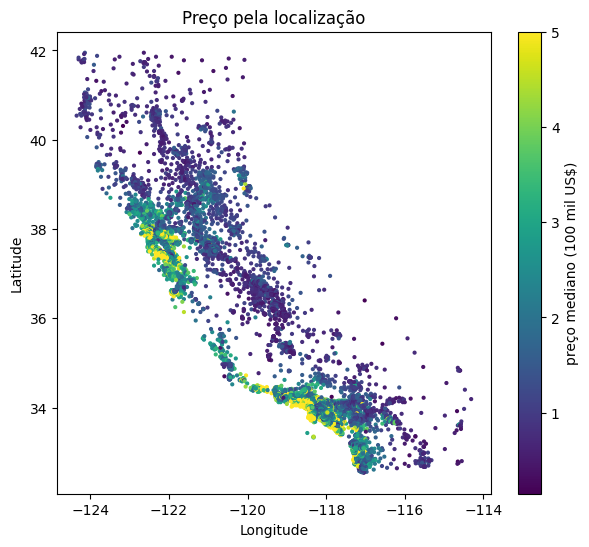

In [6]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(X['Longitude'], X['Latitude'], c=y, s=4, cmap='viridis')
plt.colorbar(sc, label='preço mediano (100 mil US$)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Preço pela localização')
plt.show()

## Treino, validação e teste

Agora são três conjuntos, na proporção 70/15/15, com `random_state` fixo para a divisão ser sempre a mesma:

- **treino** (70%): é onde os parâmetros são ajustados;
- **validação** (15%): serve para acompanhar o custo em dados que o modelo não viu durante o treino (e para decidir coisas como a taxa de aprendizado);
- **teste** (15%): fica guardado até o fim, e só é usado uma vez, para dar a nota final do modelo.

O `train_test_split` só divide em dois, então chamo ele duas vezes: primeiro separo 70% para treino, depois divido os 30% restantes ao meio.

In [7]:
x_np = X.to_numpy()
y_np = y.to_numpy().reshape(-1, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_np, y_np, test_size=0.30, random_state=42)
x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.50, random_state=42)

print('treino:   ', x_train_raw.shape)
print('validação:', x_val_raw.shape)
print('teste:    ', x_test_raw.shape)

treino:    (14448, 8)
validação: (3096, 8)
teste:     (3096, 8)


## Padronização

Mesma ideia do 2.6: o `StandardScaler` calcula média e desvio padrão **só no treino** (`fit`) e depois aplica a mesma conta na validação e no teste (`transform`). Se a média/desvio fossem calculados com tudo, informação do teste vazaria para o treino e a nota final ficaria otimista demais.

Aqui são dois scalers: um para as 8 entradas (cada coluna é padronizada separadamente) e outro para a saída.

In [8]:
x_scaler = StandardScaler().fit(x_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

def para_tensor(a):
    return torch.from_numpy(a).float()

x_train = para_tensor(x_scaler.transform(x_train_raw))
x_val   = para_tensor(x_scaler.transform(x_val_raw))
x_test  = para_tensor(x_scaler.transform(x_test_raw))

y_train = para_tensor(y_scaler.transform(y_train_raw))
y_val   = para_tensor(y_scaler.transform(y_val_raw))
y_test  = para_tensor(y_scaler.transform(y_test_raw))

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('média das colunas no treino (deve ser ~0):', x_train.mean(dim=0).numpy().round(3))
print('desvio das colunas no treino (deve ser ~1):', x_train.std(dim=0).numpy().round(3))

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
média das colunas no treino (deve ser ~0): [-0. -0.  0.  0.  0. -0. -0.  0.]
desvio das colunas no treino (deve ser ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


## Modelo

Agora com 8 entradas, a camada é `nn.Linear(8, 1)`: ela calcula

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8$$

então `model.weight` tem shape (1, 8) (um peso por variável) e `model.bias` é o $w_0$. A função de custo é o `nn.MSELoss` e o otimizador é o `optim.SGD`, igual ao 2.6.

In [9]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape)
print('bias:  ', model.bias.shape)

lr = 0.1
n_epochs = 1000
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

weight: torch.Size([1, 8])
bias:   torch.Size([1])


### Funções de treino e validação

São as mesmas do 2.6: cada época é um passo de gradiente com o conjunto de treino inteiro (full batch, são só ~14 mil linhas e 8 colunas, então é rápido), e a validação só mede o custo, sem atualizar nada.

In [10]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

## Treinamento

Escolhi `lr = 0.1` e 1000 épocas. Com 8 variáveis correlacionadas entre si (latitude e longitude, por exemplo, andam juntas), algumas direções do problema convergem bem mais devagar que outras, por isso precisa de mais épocas que no 2.6. Não dá para aumentar muito a taxa: o limite de estabilidade do gradiente descendente depende da maior curvatura do custo, e com variáveis tão correlacionadas ela é maior do que no caso com uma só variável, então valores perto de 0.5 já ficam no limite (ou passam dele e divergem).

In [11]:
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss = validate_epoch(model, criterion, x_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 100 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}')

Epoch[100/1000], Train Loss: 0.3938, Val Loss: 0.4066
Epoch[200/1000], Train Loss: 0.3908, Val Loss: 0.4039
Epoch[300/1000], Train Loss: 0.3907, Val Loss: 0.4038
Epoch[400/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[500/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[600/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[700/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[800/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[900/1000], Train Loss: 0.3907, Val Loss: 0.4037
Epoch[1000/1000], Train Loss: 0.3907, Val Loss: 0.4037


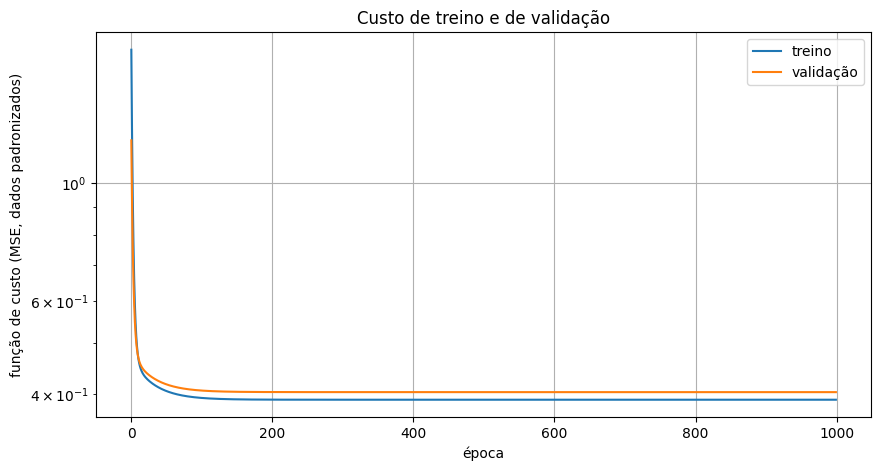

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

As duas curvas caem juntas e vão se estabilizando, ficando bem próximas uma da outra. Isso é esperado: um modelo linear com só 9 parâmetros e milhares de amostras praticamente não tem como decorar o treino (overfitting). Se tivesse um gap grande entre as curvas, seria sinal de problema.

## Avaliação no teste

Agora sim o conjunto de teste entra em cena, uma única vez. Como o MSE na escala padronizada é difícil de interpretar, calculo o **RMSE em dólares**: levo as previsões de volta para a escala original com `inverse_transform` e multiplico por 100 mil (porque `y` está em centenas de milhares).

Para saber se o modelo vale alguma coisa, comparo com um **baseline** bem bobo: um "modelo" que ignora as entradas e sempre prevê a **média de preço do treino**. Se a regressão não ganhar disso, não serve pra nada.

In [13]:
def rmse_dolares(y_pred_raw, y_real_raw):
    return np.sqrt(np.mean((y_pred_raw - y_real_raw) ** 2)) * 100_000

# previsões do modelo no teste, de volta à escala original
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)
y_pred_test_raw = y_scaler.inverse_transform(y_pred_test.numpy())

# baseline: sempre prevê a média do treino
media_treino = y_train_raw.mean()
y_base_raw = np.full_like(y_test_raw, media_treino)

rmse_modelo = rmse_dolares(y_pred_test_raw, y_test_raw)
rmse_base = rmse_dolares(y_base_raw, y_test_raw)

# R² no teste (quanto da variância do preço o modelo explica)
r2 = 1 - np.sum((y_pred_test_raw - y_test_raw) ** 2) / np.sum((y_test_raw - y_test_raw.mean()) ** 2)

print(f'RMSE do baseline (média do treino): US$ {rmse_base:,.0f}')
print(f'RMSE da regressão linear:           US$ {rmse_modelo:,.0f}')
print(f'redução do erro:                    {100 * (1 - rmse_modelo / rmse_base):.1f}%')
print(f'R² no teste:                        {r2:.3f}')

RMSE do baseline (média do treino): US$ 114,992
RMSE da regressão linear:           US$ 72,129
redução do erro:                    37.3%
R² no teste:                        0.607


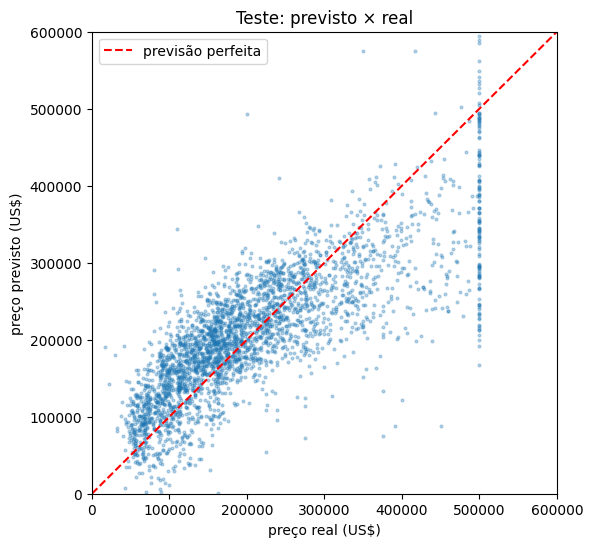

In [14]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_raw * 100_000, y_pred_test_raw * 100_000, s=4, alpha=0.3)
lim = [0, 600_000]
plt.plot(lim, lim, 'r--', label='previsão perfeita')
plt.xlim(lim); plt.ylim(lim)
plt.xlabel('preço real (US$)')
plt.ylabel('preço previsto (US$)')
plt.title('Teste: previsto × real')
plt.legend()
plt.show()

O gráfico ajuda a enxergar o que o RMSE sozinho não mostra: a nuvem segue a diagonal, mas com bastante espalhamento, e aquela coluna vertical em 500 mil são as casas "cortadas" no teto do dataset, que o modelo prevê com valores bem mais baixos.

## Os pesos aprendidos

Como as entradas e a saída foram padronizadas, o peso de cada variável diz o seguinte: *se essa variável sobe 1 desvio padrão (e as outras ficam fixas), o preço previsto muda em `peso` desvios padrão*. Vamos ver o que o modelo aprendeu.

  variavel      peso
    MedInc  0.733702
 AveBedrms  0.301019
  HouseAge  0.105508
Population -0.000764
  AveOccup -0.036026
  AveRooms -0.258815
 Longitude -0.750449
  Latitude -0.772254

bias (w0): 0.0


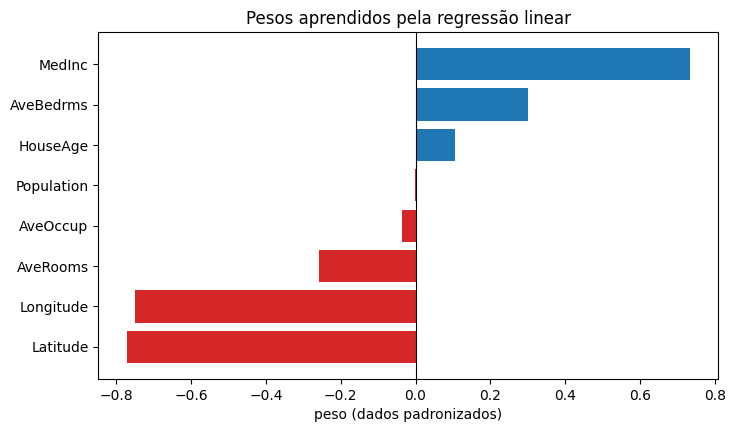

In [15]:
pesos = model.weight.detach().numpy().flatten()
df_pesos = pd.DataFrame({'variavel': X.columns, 'peso': pesos}).sort_values('peso', ascending=False)
print(df_pesos.to_string(index=False))
print('\nbias (w0):', round(model.bias.item(), 5))

plt.figure(figsize=(8, 4.5))
plt.barh(df_pesos['variavel'][::-1], df_pesos['peso'][::-1],
         color=['tab:red' if p < 0 else 'tab:blue' for p in df_pesos['peso'][::-1]])
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('peso (dados padronizados)')
plt.title('Pesos aprendidos pela regressão linear')
plt.show()

Antes de interpretar, uma conferência rápida: como o problema é linear, dá para calcular os pesos ótimos direto pela equação normal (resolvida aqui com `np.linalg.lstsq`, que é mais estável que inverter a matriz) e ver se o gradiente descendente chegou lá.

In [16]:
xb = np.hstack([np.ones((x_train.shape[0], 1)), x_train.numpy().astype(np.float64)])
w_opt, *_ = np.linalg.lstsq(xb, y_train.numpy().astype(np.float64), rcond=None)
w_treinado = np.concatenate([[model.bias.item()], pesos])

print('diferença máxima entre o treinado e o analítico:', np.abs(w_treinado - w_opt.flatten()).max())

diferença máxima entre o treinado e o analítico: 7.5335636523510274e-06


### Quais variáveis aumentam e quais diminuem o preço?

**O que mais aumenta o preço:** de longe a `MedInc`, a renda mediana do quarteirão, com o maior peso positivo. Faz todo sentido, onde o pessoal ganha mais, as casas são mais caras. Depois vêm `AveBedrms` e `HouseAge`, com pesos positivos bem menores.

**O que mais diminui o preço:** `Latitude` e `Longitude`, com pesos negativos grandes (quase do tamanho do da renda, só que pro outro lado). Isso é o litoral aparecendo: longitude mais negativa significa mais a oeste, perto do mar, e latitude menor significa mais ao sul, e é justamente onde estão as áreas caras (Los Angeles, San Diego e boa parte da Bay Area), enquanto o interior e o norte são mais baratos. Também aparece `AveRooms` com peso negativo.

**O que quase não pesa:** `Population` e `AveOccup` ficam perto de zero, então, uma vez que as outras variáveis já estão no modelo, elas não ajudam a explicar o preço.

Uma ressalva: o sinal de `AveRooms` (negativo) e o de `AveBedrms` (positivo) parece contraditório, afinal mais cômodos deveria ser melhor. O problema é que essas duas variáveis são muito correlacionadas entre si (casa com mais cômodos costuma ter mais quartos), e quando duas entradas andam juntas, o modelo divide o "crédito" entre elas de um jeito meio arbitrário. Então eu não leria os sinais dessas duas de forma isolada, o mesmo vale para latitude e longitude, que também andam juntas no mapa.

### Por que só dá para comparar os pesos entre si porque padronizamos?

Porque o peso depende da **unidade** da variável. Se `Population` estivesse em pessoas e `MedInc` em dezenas de milhares de dólares, o peso de cada uma seria "variação do preço por *pessoa* a mais" e "por *10 mil dólares* a mais", e nem faz sentido colocar esses números lado a lado. Um peso minúsculo para `Population` poderia só significar que a unidade é minúscula, não que a variável é irrelevante (basta pensar: mudar a população de pessoas para milhares de pessoas multiplica o peso por mil, sem mudar nada no modelo).

Depois de padronizar, todas as entradas têm média 0 e desvio padrão 1, então cada peso passa a significar a mesma coisa: o efeito de **subir 1 desvio padrão** naquela variável. Aí sim os tamanhos são comparáveis. Mesmo assim, "comparável" não quer dizer "causal": o modelo só mostra associações, e com variáveis correlacionadas como as que citei, a comparação precisa de cuidado.

## Conclusão

A regressão linear múltipla já entrega bastante coisa: o erro no teste fica na casa de 70 e poucos mil dólares, contra mais ou menos 115 mil do baseline que só chuta a média, e o R² fica perto de 0,6 (ou seja, o modelo explica algo como 60% da variação do preço). Para um modelo com só 9 parâmetros, que treina em segundos, eu achei um resultado bom como ponto de partida.

Mas "bom o suficiente" depende do uso, e para prever o preço de uma casa específica eu diria que **não**: um erro típico de ~70 mil dólares numa região onde o preço mediano está perto de 180 mil é muito grande, e o modelo erra feio justamente nas casas mais caras (o teto de 500 mil e a relação com a localização, que não é linear).

O que eu tentaria para melhorar, mais ou menos em ordem de esforço:

1. **Tratar o que está sujo nos dados:** os quarteirões com `AveRooms`/`AveOccup` absurdos e o teto de 500 mil (talvez tirar essas linhas do treino, ou aplicar log em algumas variáveis).
2. **Features melhores:** usar latitude e longitude de forma não linear (termos quadráticos, interação lat×lon, ou distância até o litoral/às grandes cidades), já que o preço varia por "regiões" e não em linha reta.
3. **Um modelo não linear:** uma rede com camadas ocultas (a continuação natural do curso) ou árvores/gradient boosting, que conseguem capturar essas interações sem eu precisar criar as features na mão.